In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# 01 · Data audit

**Question for this notebook:** can the trip records be trusted for a
before/after comparison, and which taxi zones are inside the toll zone?

The pipeline (`scripts/build_data.py`) reduced every monthly TLC file for
yellow taxis, green taxis and high-volume for-hire vehicles (Uber, Lyft)
from January 2022 to August 2026 to daily totals by pickup zone. This
notebook checks what was kept, confirms the CBD zone list against the fee
the trips actually paid, and measures how often trips that do *not* start
or end in the zone still pay (they pass through it), which matters for the
comparison group.

In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from congestion.panel import SERVICE_LABEL, load_zone_day
from congestion.plots import COLORS, GROUP_LABEL, mark_policy, save, style, write_metrics
from congestion.zones import BORDER_ZONES, CBD_ZONES

style()
pd.set_option("display.width", 120)

## 1. What the pipeline kept

Rows are dropped when the pickup falls outside the file's month, the trip
lasts under a minute or over four hours, the distance is negative or over
100 miles, or the fare is negative (refund and void records).

In [3]:
audit = pd.read_csv("data/processed/audit.csv")
totals = audit.groupby("service")[["rows_raw", "rows_kept"]].sum()
totals["kept_share"] = totals["rows_kept"] / totals["rows_raw"]
totals.index = totals.index.map(SERVICE_LABEL)
print(f"{audit['rows_raw'].sum():,} raw rows, {audit['rows_kept'].sum():,} trips kept "
      f"({audit['rows_kept'].sum() / audit['rows_raw'].sum():.2%}), "
      f"{audit['month'].min()} to {audit['month'].max()}")
totals

1,296,931,116 raw rows, 1,288,695,819 trips kept (99.37%), 2022-01 to 2026-08


,rows_raw,rows_kept,kept_share
service,,,
Green taxi,3216169,3091985,0.961388
Uber/Lyft,1096152946,1095507034,0.999411
Yellow taxi,197562001,190096800,0.962213


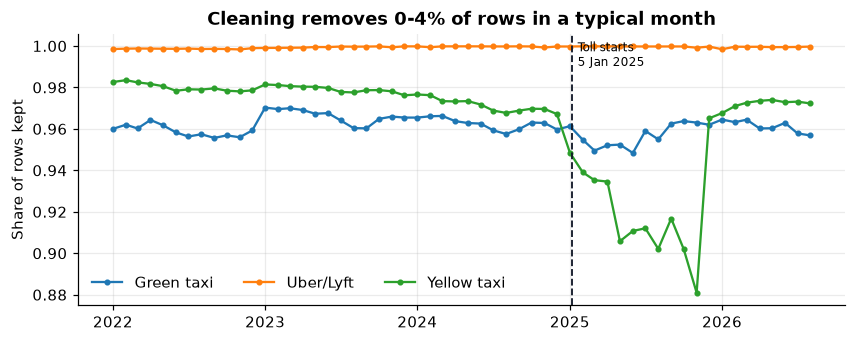

,service,month,rows_raw,rows_kept,kept_share
158,yellow,2025-11,4181444,3683754,0.880977
157,yellow,2025-10,4428699,3994681,0.901999
155,yellow,2025-08,3574091,3224253,0.902118


In [4]:
audit["kept_share"] = audit["rows_kept"] / audit["rows_raw"]
audit["month_start"] = pd.to_datetime(audit["month"] + "-01")
fig, ax = plt.subplots(figsize=(9, 3.2))
for svc, g in audit.groupby("service"):
    ax.plot(g["month_start"], g["kept_share"], marker=".", label=SERVICE_LABEL[svc])
ax.set_ylabel("Share of rows kept")
ax.set_title("Cleaning removes 0-4% of rows in a typical month")
ax.legend(ncol=3, loc="lower left")
mark_policy(ax)
save(fig, "01_rows_kept.png")
plt.show()
audit.sort_values("kept_share").head(3)[["service", "month", "rows_raw", "rows_kept", "kept_share"]]

The one outlier is yellow taxis in November 2025 (88% kept). Checking the
raw file: 9.4% of its rows have a negative fare (refund or void records
that sit next to the original trip) and a new vendor code reports 60,043
zero-length records. Both are correctly removed, so trip counts that month
are not distorted.

## 2. Which zones are in the toll zone?

The MTA's list of CBD taxi zones lives on data.ny.gov. Instead of copying
it, `scripts/derive_cbd_zones.py` recovers it from the trips: for each zone,
the share of trips that start *and* end there and carry the CBD fee
(January-March 2025).

In [5]:
ev = pd.read_csv("data/reference/cbd_zone_evidence.csv")
summary = ev.groupby("group")["hvfhv_fee_share"].agg(["count", "min", "median", "max"]).round(3)
summary.index = summary.index.map(lambda g: GROUP_LABEL.get(g, g))
summary

,count,min,median,max
group,,,,
Airports,3,0.000,0.001,0.031
60th St border,6,0.140,0.294,0.467
Toll zone (CBD),38,0.902,0.949,1.000
Rest of Manhattan,22,0.000,0.002,0.031
Outer boroughs,189,0.000,0.000,0.035


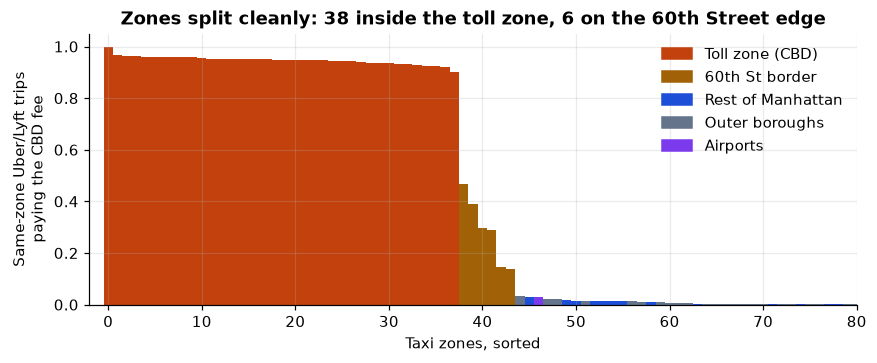

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.2))
order = ev.sort_values("hvfhv_fee_share", ascending=False).reset_index(drop=True)
ax.bar(order.index, order["hvfhv_fee_share"], width=1.0,
       color=[COLORS.get(g, COLORS["outer"]) for g in order["group"]])
ax.set_xlabel("Taxi zones, sorted")
ax.set_ylabel("Same-zone Uber/Lyft trips\npaying the CBD fee")
ax.set_title("Zones split cleanly: 38 inside the toll zone, 6 on the 60th Street edge")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORS[g], label=GROUP_LABEL[g])
                   for g in ["cbd", "border", "manhattan_north", "outer", "airport"]])
ax.set_xlim(-2, 80)
save(fig, "01_cbd_zone_evidence.png")
plt.show()

Inside the zone, 90-100% of same-zone Uber/Lyft trips pay; outside, at most
3.5%. The six border zones (Lincoln Square, Lenox Hill, Upper East Side
South, Central Park) pay 14-47% because only part of each is below 60th
Street. They are left out of every comparison (the "donut").

## 3. When the fee appears, and who pays it

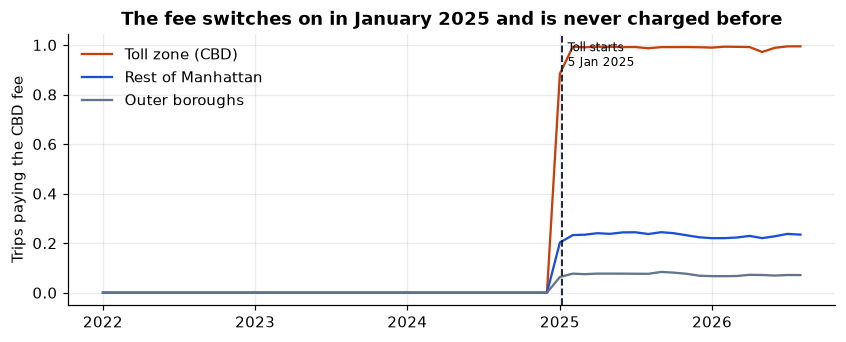

Fee-paying trips before 5 Jan 2025: 1,573, on [datetime.date(2025, 1, 4)]


In [7]:
zd = load_zone_day()
zd["month"] = zd["date"].dt.to_period("M").dt.to_timestamp()
fee = (zd[zd["group"].isin(["cbd", "manhattan_north", "outer"])]
       .groupby(["month", "group"])[["fee_trips", "trips"]].sum())
fee_share = (fee["fee_trips"] / fee["trips"]).unstack()
fig, ax = plt.subplots(figsize=(9, 3.2))
for g in fee_share.columns:
    ax.plot(fee_share.index, fee_share[g], label=GROUP_LABEL[g], color=COLORS[g])
ax.set_ylabel("Trips paying the CBD fee")
ax.set_title("The fee switches on in January 2025 and is never charged before")
ax.legend()
mark_policy(ax)
save(fig, "01_fee_share.png")
plt.show()

pre = zd[(zd["date"] < "2025-01-05") & (zd["fee_trips"] > 0)]
pre_fee = int(pre["fee_trips"].sum())
print(f"Fee-paying trips before 5 Jan 2025: {pre_fee:,}, on", sorted(pre["date"].dt.date.unique()))

The only fee-paying trips before the launch started on the evening of
4 January and were still running when the toll switched on at midnight.

Trips from the comparison zones that do **not** end in the CBD can still
pay if they drive through it (say, Brooklyn to the Upper East Side over the
Manhattan Bridge). The comparison outcome is "trips that don't end in the
CBD", so these through-trips are the treated part hiding in the control
group. The estimate of that share: fee-paying trips minus trips into the
CBD, divided by trips not into the CBD.

In [8]:
y25 = zd[(zd["date"] >= "2025-01-05") & (zd["date"] <= "2025-12-31")]
through = {}
for g in ["manhattan_north", "outer"]:
    d = y25[y25["group"] == g]
    through[g] = float(((d["fee_trips"] - d["trips_to_cbd"]).clip(lower=0).sum())
                       / (d["trips"] - d["trips_to_cbd"]).sum())
cbd25 = y25[y25["group"] == "cbd"]
fee_share_cbd = {svc: float(g["fee_trips"].sum() / g["trips"].sum())
                 for svc, g in cbd25.groupby("service")}
pd.DataFrame({"through-trip share": through}).style.format("{:.1%}")

,through-trip share
manhattan_north,4.8%
outer,1.1%


About 5% of comparison trips from the rest of Manhattan and 1% from the
outer boroughs pass through the zone and pay. That is small: if the toll
changed their number by X%, it would move the comparison by about
0.05 × X%, biasing the estimates slightly toward zero.

Not every trip starting in the CBD pays either (the fee applies once per
trip and some trips are exempt or recorded without it), so the CBD group
is "trips exposed to the fee", not "trips that paid".

**Green taxis are left out of the analysis.** They may only pick up street
hails above West 110th and East 96th Street, and fewer than 1% of the green
trips recorded as starting in the CBD paid the fee: those records are
mostly pre-arranged trips or zone errors, not toll-zone demand.

In [9]:
fees_2025 = float(y25["fee_sum"].sum())
print(f"CBD fees on taxi and ride-hail trips in 2025: ${fees_2025 / 1e6:,.1f}M")
print({SERVICE_LABEL[k]: f"{v:.1%}" for k, v in fee_share_cbd.items()})

CBD fees on taxi and ride-hail trips in 2025: $148.7M
{'Green taxi': '0.6%', 'Uber/Lyft': '99.1%', 'Yellow taxi': '99.2%'}


In [10]:
write_metrics("data_audit", {
    "first_month": audit["month"].min(),
    "last_month": audit["month"].max(),
    "rows_raw": int(audit["rows_raw"].sum()),
    "trips_kept": int(audit["rows_kept"].sum()),
    "kept_share": float(audit["rows_kept"].sum() / audit["rows_raw"].sum()),
    "n_cbd_zones": len(CBD_ZONES),
    "n_border_zones": len(BORDER_ZONES),
    "cbd_fee_share_min": float(ev.loc[ev["group"] == "cbd", "hvfhv_fee_share"].min()),
    "outside_fee_share_max": float(ev.loc[ev["group"].isin(["manhattan_north", "outer", "airport"]),
                                          "hvfhv_fee_share"].max()),
    "fee_trips_before_policy": pre_fee,
    "through_trip_share_manhattan": through["manhattan_north"],
    "through_trip_share_outer": through["outer"],
    "cbd_origin_fee_share_2025": fee_share_cbd,
    "fees_2025_usd": fees_2025,
})

Saved reports/metrics/data_audit.json
